Batch-run the full EPL-derived framework across the 9 leagues

Each league runs in a fresh kernel from `full_league_analysis.ipynb`. Executed nbs + summary tables are saved separately, downloaded input files aren't modified. Test EPL first, then expand the league selection. Bookmaker comparisons need league-specific odds sources -> not automated here.

In [1]:
from pathlib import Path
import pandas as pd
import nbformat
from nbclient import NotebookClient
from IPython.display import display

PROJECT = (Path.cwd().parent if Path.cwd().name == "src" else Path.cwd())  # project folder (run from it or from src)
TEMPLATE = PROJECT / "src" / "full_league_analysis.ipynb"
DATA_ROOT = PROJECT / "data"
RESULTS_ROOT = PROJECT / "results" / "full"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
IMAGES_ROOT = PROJECT / "images"  # every fig from every nb goes here
IMAGES_ROOT.mkdir(parents=True, exist_ok=True)
SELECTED = ["epl", "laliga", "bundesliga", "eredivisie", "ligamx", "seriea", "brasileiro", "ligue1", "ucl"]  # ["epl"] for a quick test
BOOTSTRAPS = 1000  # final setting for the report (300 for a quick test)
assert TEMPLATE.is_file(), f"Template not found: {TEMPLATE}"
print("Selected:", SELECTED)

Selected: ['epl', 'laliga', 'bundesliga', 'eredivisie', 'ligamx', 'seriea', 'brasileiro', 'ligue1', 'ucl']


In [2]:
runs=[]
for league in SELECTED:
    print("Starting",league,flush=True)
    run=nbformat.read(TEMPLATE,as_version=4)
    parameters=chr(10).join([f"LEAGUE = {league!r}", f"DATA_ROOT = {str(DATA_ROOT)!r}", f"RESULTS_ROOT = {str(RESULTS_ROOT)!r}", f"IMAGES_ROOT = {str(IMAGES_ROOT)!r}", f"B_OVERRIDE = {BOOTSTRAPS}"])
    run.cells.insert(0,nbformat.v4.new_code_cell(parameters))
    try:
        client=NotebookClient(run,timeout=1800,kernel_name="python3",resources={"metadata":{"path":str(PROJECT)}},allow_errors=False)
        client.execute()
        status="success"
        detail=""
    except Exception as exc:
        status="failed"
        detail=f"{type(exc).__name__}: {str(exc)[-1200:]}"
        print(detail[-600:])
    folder=RESULTS_ROOT/league
    folder.mkdir(parents=True,exist_ok=True)
    nbformat.write(run,folder/"executed_full_analysis.ipynb")
    runs.append({"league":league,"status":status,"details":detail})
    pd.DataFrame(runs).to_csv(RESULTS_ROOT/"run_log.csv",index=False)
    print(league,status,"| saved:",folder/"executed_full_analysis.ipynb",flush=True)
display(pd.DataFrame(runs))

Starting epl


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


epl success | saved: /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/full/epl/executed_full_analysis.ipynb


Starting laliga


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


laliga success | saved: /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/full/laliga/executed_full_analysis.ipynb


... (18 outputs left out)

Starting ucl


[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


ucl success | saved: /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/full/ucl/executed_full_analysis.ipynb


,league,status,details
0,epl,success,
1,laliga,success,
2,bundesliga,success,
3,eredivisie,success,
4,ligamx,success,
5,seriea,success,
6,brasileiro,success,
7,ligue1,success,
8,ucl,success,


Cross-league comparisons

Run once results are produced (or after combining folders from partner). Only reads saved summaries, doesn't rerun the analyses.

,league,horizon,matches,brier_3way,paired_matches,median_mean_spread,draw_gap,mean_abs_sum_mid_deviation,model_rounded_fee_arbs,indicative_no_fee_arbs,hourly_complete_rows,hourly_model_fee_arbs,hourly_no_fee_arbs
0,brasileiro,1d,410,0.5809,357,0.0133,0.0016,0.0082,0,3,53166,0,723
2,bundesliga,1d,387,0.5658,383,0.0133,0.0124,0.0048,0,1,60603,0,185
4,epl,1d,485,0.6095,478,0.0133,0.0315,0.0060,0,3,85079,0,413
6,eredivisie,1d,325,0.5981,134,0.0200,0.0656,0.0073,0,1,28077,0,285
8,laliga,1d,489,0.5633,454,0.0133,-0.0045,0.0049,0,1,77778,2,279
10,ligamx,1d,327,0.6279,137,0.0133,0.0176,0.0110,0,14,33230,0,837
12,ligue1,1d,395,0.5778,379,0.0133,-0.0033,0.0048,0,2,57972,0,219
14,seriea,1d,485,0.5671,465,0.0133,-0.0225,0.0046,0,1,76122,0,197
16,ucl,1d,353,0.5231,253,0.0100,-0.0226,0.0064,0,3,50389,0,793
1,brasileiro,7d,370,0.6093,357,0.0767,-0.0248,0.0929,0,1,53166,0,723


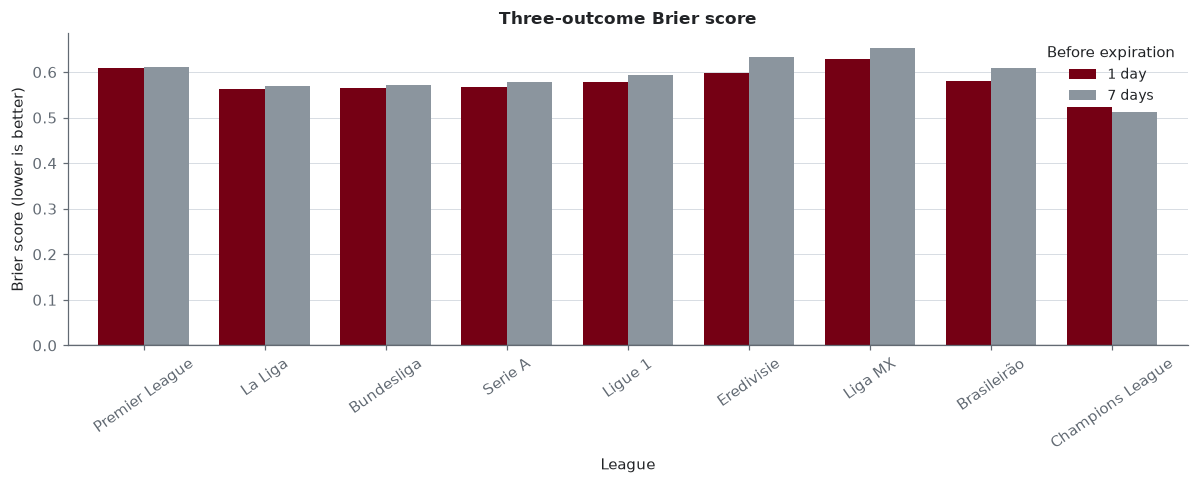

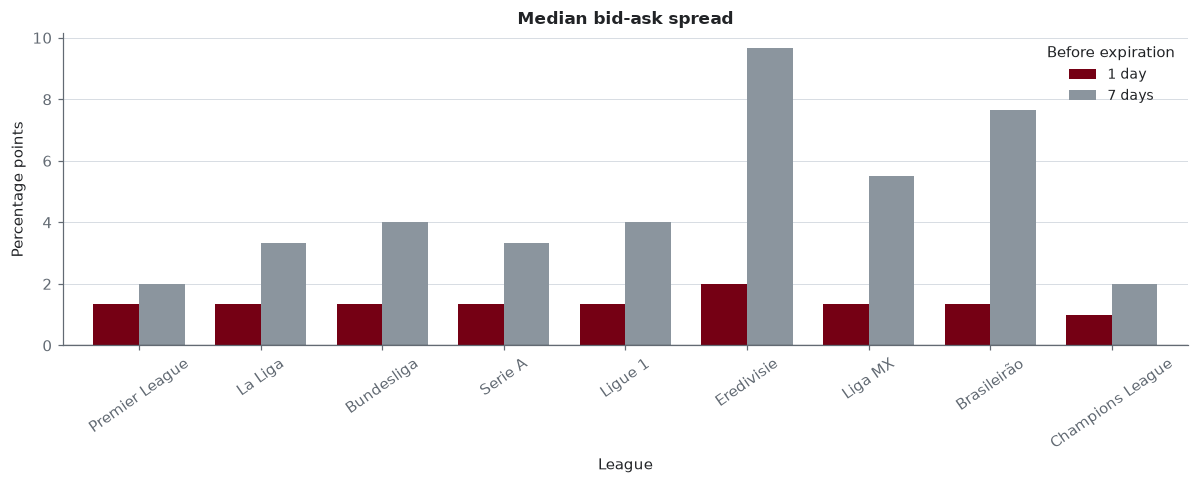

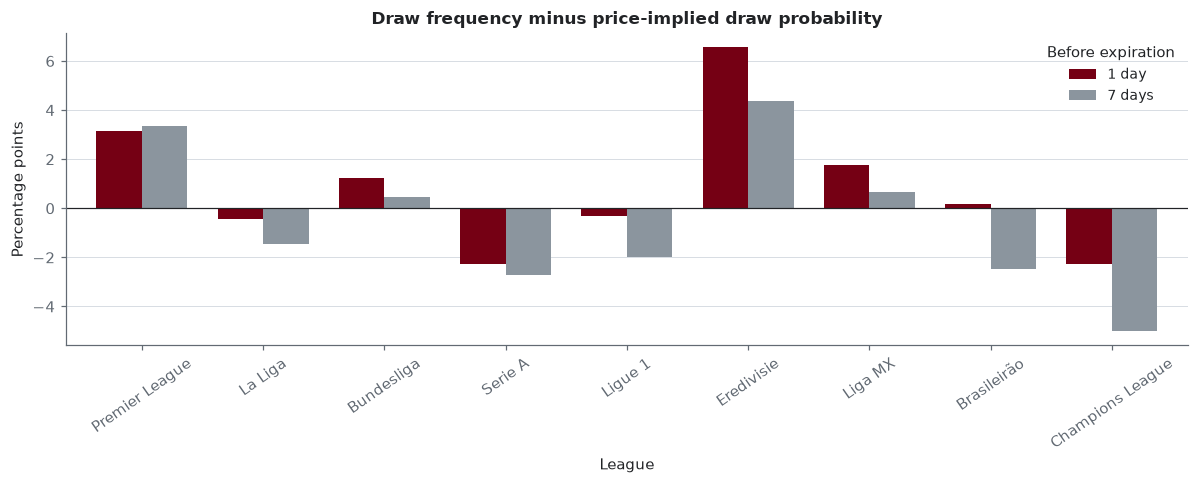

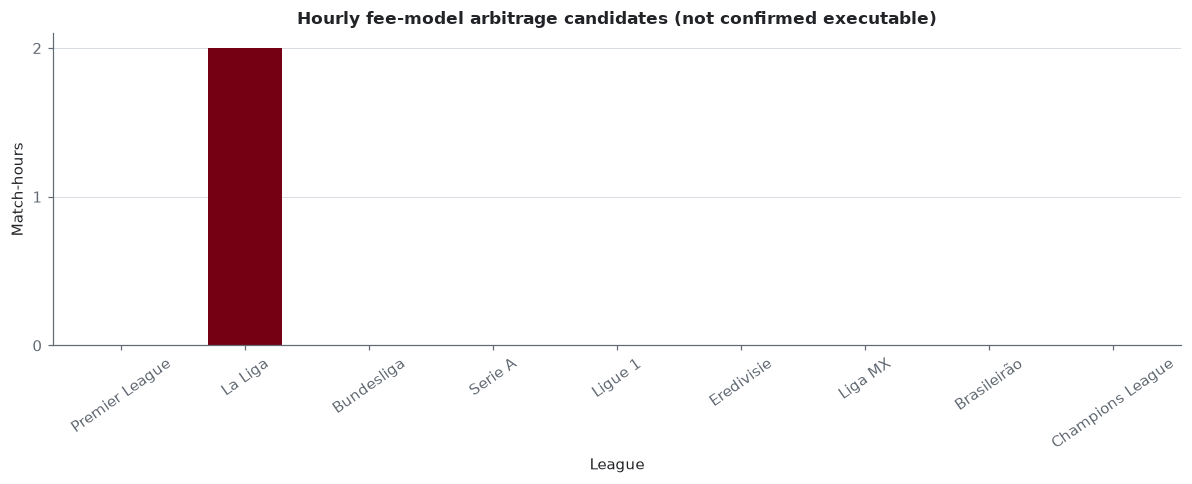

Saved comparison table and figures: /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/results/full | /Users/ralphnader/Library/CloudStorage/OneDrive-Personal/MIT/Lectures/Fall 2026/Financial Engineering/Projects/Project1/images


In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from cycler import cycler

MIT = {
    "mit_red": "#750014",
    "red": "#A31F34",
    "light_red": "#D98C97",
    "bright_red": "#FF1423",
    "silver": "#8B959E",
    "dark_gray":"#626A73",
    "light_gray": "#B8C2CC",
    "black": "#212326",
}
MIT_CYCLE = [MIT[k] for k in ["mit_red", "silver", "light_red", "dark_gray", "red", "light_gray", "black"]]
HORIZON_COLORS = {"1d": MIT["mit_red"], "7d": MIT["silver"]}

mpl.rcParams.update({
    "axes.prop_cycle": cycler(color=MIT_CYCLE),
    "axes.edgecolor": MIT["dark_gray"], "axes.labelcolor": MIT["black"], "text.color": MIT["black"],
    "xtick.color": MIT["dark_gray"], "ytick.color": MIT["dark_gray"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": MIT["light_gray"], "grid.alpha": 0.6, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})

LEAGUE_NAMES = {"epl": "Premier League", "laliga": "La Liga", "bundesliga": "Bundesliga", "seriea": "Serie A",
                "ligue1": "Ligue 1", "eredivisie": "Eredivisie", "ligamx": "Liga MX", "brasileiro": "Brasileirão",
                "ucl": "Champions League"}
FIG_DIR = IMAGES_ROOT

files = sorted(RESULTS_ROOT.glob("*/summary.csv"))
assert files, "No summary files yet. Run the analysis first."
combined = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
combined = combined.drop_duplicates(["league", "horizon"], keep="last")
combined.to_csv(RESULTS_ROOT / "all_leagues_full_comparison.csv", index=False)
display(combined.sort_values(["horizon", "league"]).round(4))

order = [l for l in LEAGUE_NAMES if l in set(combined["league"])]  # fixed order, full names
for metric, label, unit, mult in [
    ("brier_3way", "Three-outcome Brier score", "Brier score (lower is better)", 1),
    ("median_mean_spread", "Median bid-ask spread", "Percentage points", 100),
    ("draw_gap", "Draw frequency minus price-implied draw probability", "Percentage points", 100),
]:
    w = combined.pivot(index="league", columns="horizon", values=metric).reindex(order) * mult
    w.index = [LEAGUE_NAMES[l] for l in w.index]
    ax = w.plot.bar(figsize=(11, 4.5), rot=35, width=0.75,
                    color=[HORIZON_COLORS.get(h, MIT["dark_gray"]) for h in w.columns])
    ax.axhline(0, color=MIT["black"], lw=0.8)
    ax.set(title=label, xlabel="League", ylabel=unit)
    ax.grid(axis="x", visible=False)
    ax.legend(ax.containers, ["1 day" if h == "1d" else "7 days" for h in w.columns], title="Before expiration")
    plt.tight_layout()
    for ext in ("png", "pdf"):
        plt.savefig(FIG_DIR / f"compare_{metric}.{ext}")
    plt.show()

# hourly candidates use every pre-match hour -> 1d and 7d rows carry the same count, so 1 bar/league
arbs = combined.drop_duplicates("league").set_index("league")["hourly_model_fee_arbs"].reindex(order)
arbs.index = [LEAGUE_NAMES[l] for l in arbs.index]
ax = arbs.plot.bar(figsize=(11, 4.5), rot=35, width=0.6, color=MIT["mit_red"])
ax.set(title="Hourly fee-model arbitrage candidates (not confirmed executable)", xlabel="League", ylabel="Match-hours")
ax.yaxis.get_major_locator().set_params(integer=True)
ax.grid(axis="x", visible=False)
plt.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(FIG_DIR / f"compare_hourly_model_fee_arbs.{ext}")
plt.show()
print("Saved comparison table and figures:", RESULTS_ROOT.resolve(), "|", FIG_DIR.resolve())
